In [1]:
# Experiment 05 — Single-Qubit Gates: Pauli X, Y, Z and Hadamard

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator

# Define the four single-qubit gates
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)

print("Pauli-X Gate:\n", X)
print("\nPauli-Y Gate:\n", Y)
print("\nPauli-Z Gate:\n", Z)
print("\nHadamard Gate:\n", H)

Pauli-X Gate:
 [[0 1]
 [1 0]]

Pauli-Y Gate:
 [[ 0.+0.j -0.-1.j]
 [ 0.+1.j  0.+0.j]]

Pauli-Z Gate:
 [[ 1  0]
 [ 0 -1]]

Hadamard Gate:
 [[ 0.70710678  0.70710678]
 [ 0.70710678 -0.70710678]]


In [3]:
# Create the initial |0> state
initial_state = Statevector([1, 0])

# Apply each gate to the initial state
for name, gate in [("X", X), ("Y", Y), ("Z", Z), ("H", H)]:
    result = initial_state.evolve(Operator(gate))

    print(f"\n{name} Gate:")
    print("Statevector:", result.data)
    print("Probabilities:", result.probabilities_dict())


X Gate:
Statevector: [0.+0.j 1.+0.j]
Probabilities: {np.str_('1'): np.float64(1.0)}

Y Gate:
Statevector: [0.+0.j 0.+1.j]
Probabilities: {np.str_('1'): np.float64(1.0)}

Z Gate:
Statevector: [1.+0.j 0.+0.j]
Probabilities: {np.str_('0'): np.float64(1.0)}

H Gate:
Statevector: [0.70710678+0.j 0.70710678+0.j]
Probabilities: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


X Gate Circuit:


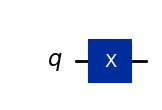

Y Gate Circuit:


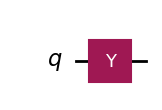

Z Gate Circuit:


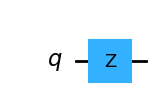

H Gate Circuit:


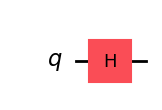

In [4]:
# Create a circuit for each gate
gates = ["x", "y", "z", "h"]

for gate in gates:
    qc = QuantumCircuit(1)

    # Apply the selected gate
    getattr(qc, gate)(0)

    print(f"{gate.upper()} Gate Circuit:")
    display(qc.draw("mpl"))

X Gate Counts: {np.str_('1'): np.int64(1024)}


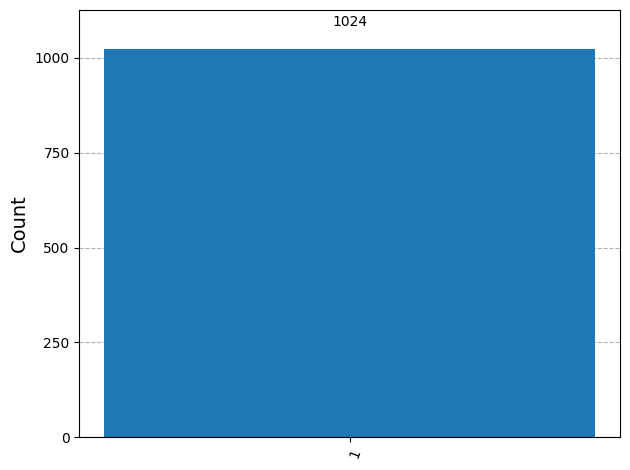

Y Gate Counts: {np.str_('1'): np.int64(1024)}


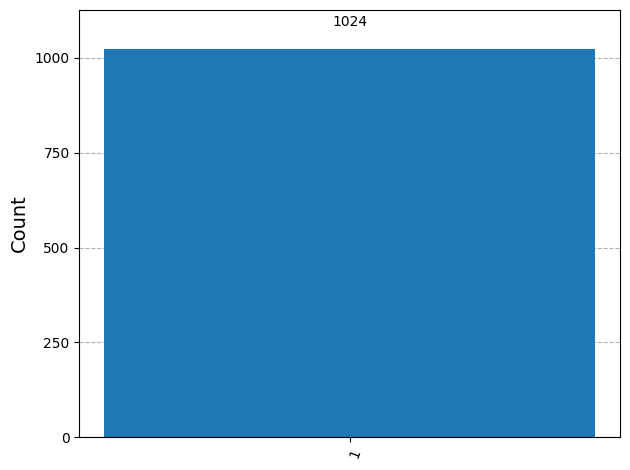

Z Gate Counts: {np.str_('0'): np.int64(1024)}


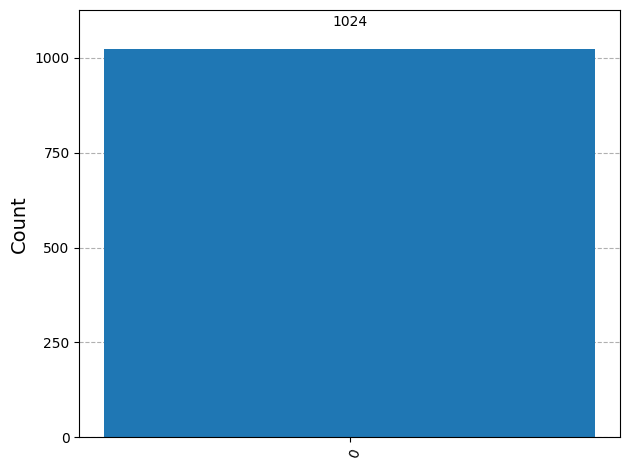

H Gate Counts: {np.str_('0'): np.int64(515), np.str_('1'): np.int64(509)}


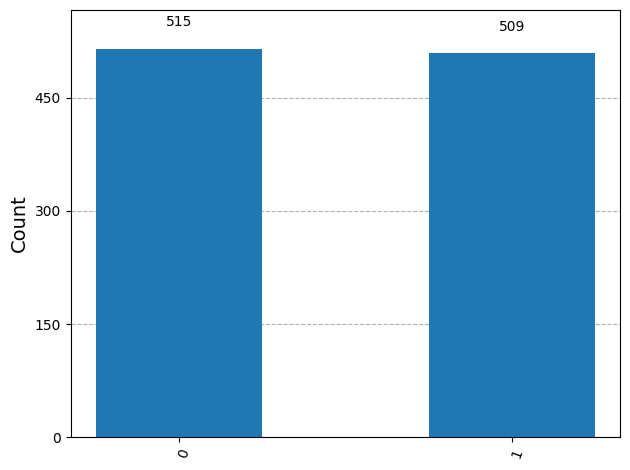

In [5]:
from qiskit.visualization import plot_histogram

# Measure the output of each gate
for gate in gates:
    qc = QuantumCircuit(1)
    getattr(qc, gate)(0)

    # Get the statevector and sample 1024 measurements
    state = Statevector.from_instruction(qc)
    state.seed(42)
    counts = state.sample_counts(shots=1024)

    print(f"{gate.upper()} Gate Counts:", counts)
    display(plot_histogram(counts))